# Лабораторная 4. Дообучение под узкую задачу

Луценко Вячеслав Александрович, М092501(77), очное отделение.

Обучаю LoRA для оценки отзывов по шкале 1-5. Базовая модель Qwen3-0.6B заморожена. После обучения `run.py` сравнивает zero-shot, few-shot и адаптер на одной тестовой части.

Ноутбук запускается из корня проекта или из `lab04/`. Пакеты перечислены в `requirements.txt`. Данные можно передать через `LAB_DATA`, иначе они берутся из открытого набора HF.

In [1]:
from pathlib import Path
from collections import Counter
import json
import os
import sys
import torch
import psutil
from transformers import AutoTokenizer

HERE = Path("lab04") if Path("lab04/train.py").is_file() else Path(".")
HERE = HERE.resolve()
sys.path.insert(0, str(HERE.parent))
from lab04.classification import MODEL, MODEL_REVISION, ReviewPrompt, load_data, select_balanced
from lab04.train import train_lora

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Модель:", MODEL)
print("Ревизия:", MODEL_REVISION)

Python: 3.13.0
PyTorch: 2.15.0+xpu
Модель: Qwen/Qwen3-0.6B
Ревизия: c1899de289a04d12100db370d81485cdf75e47ca


## Данные

Для обучения беру по 1000 примеров каждого класса из train с seed=42. Валидационная и тестовая части не участвуют в обучении. Исходные метки 0-4 преобразуются в оценки 1-5.

In [2]:
dataset = load_data(os.environ.get("LAB_DATA"))
selected = select_balanced(dataset["train"], per_class=1000, seed=42)
print("Размеры частей:", {name: len(split) for name, split in dataset.items()})
print("Обучение по оценкам:", dict(sorted(Counter(int(row["label"]) + 1 for row in selected).items())))
print("Всего обучающих примеров:", len(selected))

Размеры частей: {'train': 50000, 'validation': 5000, 'test': 2048}
Обучение по оценкам: {1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000}
Всего обучающих примеров: 5000


## Проверка маски

Шаблон чата общий с оценкой. `enable_thinking=False` оставляет пустой блок размышлений. В labels промпт закрыт значением -100, открыты только цифра и EOS. Последний токен промпта предсказывает цифру, а цифра предсказывает EOS.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=MODEL_REVISION)
tokenizer.pad_token = tokenizer.eos_token
builder = ReviewPrompt(tokenizer)
example = selected[0]
record = builder.training_record(example["text"], int(example["label"]) + 1)
print("Длина примера:", len(record["input_ids"]))
print("Токенов промпта с маской:", record["labels"].count(-100))
print("Токенов ответа:", sum(label != -100 for label in record["labels"]))
print("Ответ:", tokenizer.decode(record["labels"][-2:]))
assert all(label == -100 for label in record["labels"][:-2])
assert len(record["input_ids"]) <= 256

Длина примера: 176
Токенов промпта с маской: 174
Токенов ответа: 2
Ответ: 2<|im_end|>


## Обучение

Ранг 8, alpha=16, семь линейных модулей, AdamW с lr=2e-4, одна эпоха, эффективный батч 8. Для меньшего расхода памяти выход в словарь считаю только для двух позиций ответа: это тот же masked cross-entropy. Проверка равенства обычному лоссу есть в `test_classification.py`.

На компьютере с 32 ГБ CPU использую микробатч 8; на Intel Arc использую BF16 и микробатч 1 с накоплением градиента; на других GPU — 4. Контрольная точка записывается каждые 100 шагов и не попадает в Git. Для продолжения прерванного запуска можно задать `LAB_RESUME=1`.

In [4]:
ARTIFACTS = HERE / "artifacts"
has_cuda = torch.cuda.is_available()
has_mps = torch.backends.mps.is_available()
has_xpu = hasattr(torch, "xpu") and torch.xpu.is_available()
micro_batch = 1 if has_xpu else (4 if has_cuda or has_mps or psutil.virtual_memory().total < 24 * 1024**3 else 8)
print("Микробатч:", micro_batch, "| Эффективный батч: 8")
config = train_lora(
    dataset=dataset,
    output_directory=ARTIFACTS,
    per_class=1000,
    micro_batch=micro_batch,
    threads=8,
    seed=42,
    resume=os.environ.get("LAB_RESUME") == "1",
)
print(json.dumps(config, ensure_ascii=False, indent=2))

Микробатч: 1 | Эффективный батч: 8


Обучение: 5000 примеров, 625 шагов, микробатч 1, устройство xpu


Обучаемых параметров: 5,046,272 / 601,096,192 (0.840%)


Маска первого примера: 174 токенов промпта, 2 токена ответа


Шаг 1/625: loss=0.7004, время=0.1 мин


Шаг 25/625: loss=0.7683, время=1.3 мин


... (22 outputs left out)

Шаг 600/625: loss=0.3654, время=39.8 мин


Шаг 625/625: loss=0.3891, время=41.1 мин


Адаптер сохранен; обучение 41.12 мин, пик памяти 1.99 ГБ


{
  "model": "Qwen/Qwen3-0.6B",
  "model_revision": "c1899de289a04d12100db370d81485cdf75e47ca",
  "dataset": "mteb/GeoreviewClassification",
  "lora_r": 8,
  "lora_alpha": 16,
  "lora_dropout": 0.05,
  "target_modules": [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj"
  ],
  "trainable_params": 5046272,
  "total_params": 601096192,
  "trainable_pct": 0.8395115569123419,
  "train_examples": 5000,
  "epochs": 1,
  "steps": 625,
  "batch": 8,
  "micro_batch": 1,
  "lr": 0.0002,
  "max_len": 256,
  "review_budget": 167,
  "train_minutes": 41.1188876833335,
  "peak_memory_gb": 1.9939804077148438,
  "device": "xpu",
  "dtype": "torch.bfloat16",
  "amp_dtype": "torch.bfloat16",
  "seed": 42,
  "data_sha256": "fc156097e1ccaf39e7657f125125958dd167e9538bcba7e33559a54b6f841862",
  "started_at_utc": "2026-11-13T11:15:35.768407+00:00",
  "finished_at_utc": "2026-11-13T11:56:43.171755+00:00"
}


## Кривая и сохраненный адаптер

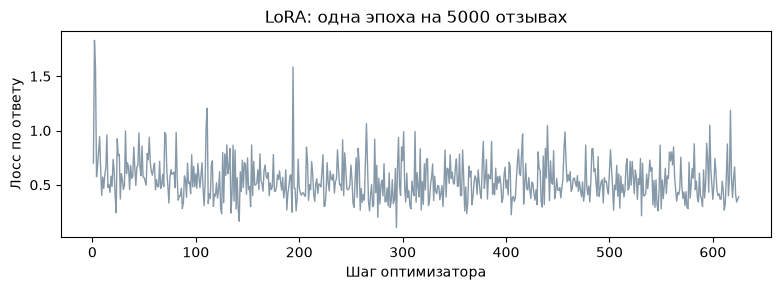

Файлы адаптера: ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
Обучаемая доля: 0.840%
Время: 41.12 мин; пик памяти: 1.99 ГБ
Далее: python lab04/run.py --fast, затем полный python lab04/run.py


In [5]:
import csv
import matplotlib.pyplot as plt

with (ARTIFACTS / "train_log.csv").open(encoding="utf-8", newline="") as stream:
    curve = list(csv.DictReader(stream))
steps = [int(row["step"]) for row in curve]
losses = [float(row["loss"]) for row in curve]
figure, axis = plt.subplots(figsize=(8, 3))
axis.plot(steps, losses, color="#46627a", linewidth=1, alpha=0.65)
axis.set_xlabel("Шаг оптимизатора")
axis.set_ylabel("Лосс по ответу")
axis.set_title("LoRA: одна эпоха на 5000 отзывах")
figure.tight_layout()
figure.savefig(ARTIFACTS / "train_loss.png", dpi=140)
plt.show()

adapter = ARTIFACTS / "adapter"
assert (adapter / "adapter_model.safetensors").is_file()
print("Файлы адаптера:", sorted(path.name for path in adapter.iterdir() if path.is_file()))
print(f"Обучаемая доля: {config['trainable_pct']:.3f}%")
print(f"Время: {config['train_minutes']:.2f} мин; пик памяти: {config['peak_memory_gb']:.2f} ГБ")
print("Далее: python lab04/run.py --fast, затем полный python lab04/run.py")

Снижение лосса само по себе не доказывает качество классификации. Итоговый вывод сделаю по макро-F1 и ошибке в звездах на тесте; ответы без цифры учитываются как ошибки. Тестовые метки при обучении не используются.